# 01 — Fundamentos e Organizacao de Dados

**Objetivos de aprendizagem:** classificar variáveis, identificar granularidade e construir frequências e gráficos apropriados

**Pré-requisitos:** Python e Pandas

**Origem:** Slides, aulas 01a–01b, páginas 8–56; tabela de candidatos transcrita da página 22. Conteúdos adicionais estão identificados como **Aprofundamento**.

**Convenção:** `datasets/` reúne dados de entrada; `outputs/` reúne resultados. Dados inventados para demonstrações são sempre identificados como *sintéticos*.

### Materiais complementares

- [Guia Técnico](./reference_materials/01_fundamentos_e_organizacao_de_dados.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_fundamentos_e_organizacao_de_dados.pdf)


## Preparação do ambiente

Execute a célula abaixo. Os notebooks são independentes e não dependem de variáveis definidas em outros arquivos.

> **Resultados reproduzíveis:** gráficos PNG e tabelas CSV selecionados são gravados automaticamente em `outputs/` ao executar as células na ordem. Os arquivos em `datasets/` são preservados. Esta disciplina usa Matplotlib, não o renderer `iframe` do Plotly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Execute o JupyterLab com o diretório desta disciplina como raiz.
BASE = Path.cwd()
DATASETS = BASE / "datasets"
OUTPUTS = BASE / "outputs"
DATASETS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

def ler_dataset(nome):
    caminho = DATASETS / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Dataset não encontrado: {caminho}. Abra o JupyterLab na raiz da disciplina.")
    return pd.read_csv(caminho)

RNG = np.random.default_rng(42)

## 1. População, unidade e variáveis

**População** é o conjunto de unidades de interesse; **amostra** é um subconjunto observado. A **unidade de análise** determina o significado de uma linha. Variáveis qualitativas são nominais ou ordinais; quantitativas são discretas ou contínuas. Um identificador numérico, como `id`, não é uma variável quantitativa para calcular média.

In [2]:
df = ler_dataset('candidatos_reconstruidos.csv')
display(df.head())
print('Unidade de análise: um candidato; linhas:',len(df),'colunas:',df.shape[1]); assert df['id'].is_unique

,id,sexo,idade,escolaridade,empregos_anteriores
0,1,F,18,Medio,0.0
1,2,F,19,Medio,NaN
2,3,F,22,Medio,1.0
3,4,M,20,Fundamental,1.0
4,5,F,24,Fundamental,2.0


Unidade de análise: um candidato; linhas: 20 colunas: 5


## 2. Frequências e valores ausentes

A **frequência absoluta** conta unidades; a **relativa** divide pelo total adequado. Decida se valores ausentes entram como categoria explícita e declare o denominador. O `value_counts(dropna=False)` inclui ausentes.

In [3]:
freq = df['sexo'].value_counts(dropna=False).rename('n').to_frame()
freq['proporcao'] = freq['n'] / len(df)
freq['percentual'] = 100*freq['proporcao']
display(freq)
assert freq['n'].sum()==len(df)
print(df['empregos_anteriores'].value_counts(dropna=False).sort_index())

,n,proporcao,percentual
sexo,,,
F,13,0.65,65.0
M,7,0.35,35.0


empregos_anteriores
0.0    4
1.0    7
2.0    4
3.0    2
4.0    2
NaN    1
Name: count, dtype: int64


In [4]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
freq.to_csv(OUTPUTS / '01_frequencia_sexo.csv', encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 3. Tabelas de dupla entrada

Uma tabela cruzada mostra combinações de categorias. A normalização por linha responde a uma pergunta diferente da normalização pelo total.

In [5]:
tab = pd.crosstab(df['sexo'], df['escolaridade'])
display(tab)
display(pd.crosstab(df['sexo'],df['escolaridade'],normalize='index').round(3))

escolaridade,Fundamental,Medio,Superior
sexo,,,
F,3,8,2
M,2,5,0


escolaridade,Fundamental,Medio,Superior
sexo,,,
F,0.231,0.615,0.154
M,0.286,0.714,0.000


In [6]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
tab.to_csv(OUTPUTS / '01_escolaridade_por_sexo.csv', encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 4. Agrupamento em classes

Para uma variável quantitativa contínua, classes têm limites explícitos e a escolha da largura altera o histograma. `pd.cut` usa por padrão intervalos abertos à esquerda e fechados à direita; ajustamos conscientemente os limites.

idade
(16.999, 19.0]    7
(19.0, 21.0]      6
(21.0, 23.0]      3
(23.0, 26.0]      4
Name: count, dtype: int64

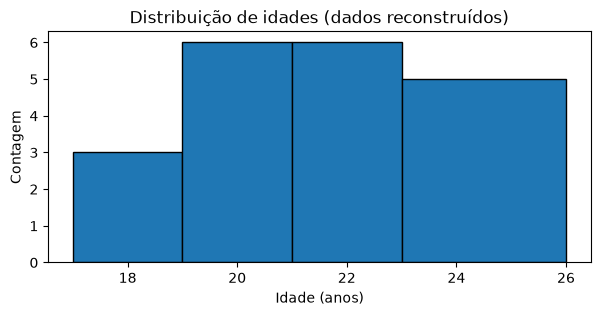

In [7]:
idades=df['idade']; classes=pd.cut(idades,bins=[17,19,21,23,26],include_lowest=True)
display(classes.value_counts(sort=False))
fig,ax=plt.subplots(figsize=(7,3));ax.hist(idades,bins=[17,19,21,23,26],edgecolor='black');ax.set(xlabel='Idade (anos)',ylabel='Contagem',title='Distribuição de idades (dados reconstruídos)');fig.savefig(OUTPUTS / '01_histograma_idades.png', dpi=160, bbox_inches='tight');plt.show()

## 5. Escolha dos gráficos

Barras: categorias. Histograma: distribuição numérica. Pareto: categorias ordenadas por frequência. Um gráfico de setores só é defensável quando as categorias são poucas e compõem um todo.

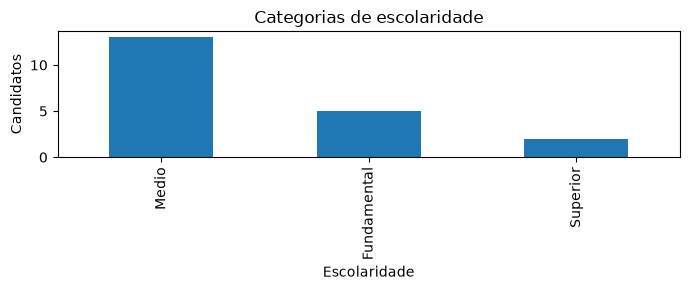

,frequencia,percentual_acumulado
escolaridade,,
Medio,13,65.0
Fundamental,5,90.0
Superior,2,100.0


In [8]:
f=df['escolaridade'].value_counts()
fig,ax=plt.subplots(figsize=(7,3));f.plot.bar(ax=ax);ax.set(xlabel='Escolaridade',ylabel='Candidatos',title='Categorias de escolaridade');plt.tight_layout();fig.savefig(OUTPUTS / '01_escolaridade_barras.png', dpi=160, bbox_inches='tight');plt.show()
acum=100*f.cumsum()/f.sum();display(pd.DataFrame({'frequencia':f,'percentual_acumulado':acum.round(1)}))

In [9]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'frequencia': f, 'percentual_acumulado': acum.round(1)}).to_csv(OUTPUTS / '01_escolaridade_pareto.csv', encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


### Exercício resolvido — Frequência de emprego não informado

**Solução comentada:**

In [10]:
faltantes=df['empregos_anteriores'].isna().sum(); taxa=faltantes/len(df)
print(f'Não declarados: {faltantes} de {len(df)} = {taxa:.1%}');assert faltantes==1

Não declarados: 1 de 20 = 5.0%


**Interpretação:** Há uma resposta não declarada; excluí-la silenciosamente altera o denominador das proporções.

### Exercício resolvido — Frequência dos candidatos por sexo

**Solução comentada:**

In [11]:
homens=(df['sexo']=='M').sum(); mulheres=(df['sexo']=='F').sum()
print(homens,mulheres); assert (homens,mulheres)==(7,13)

7 13


**Interpretação:** A tabela original informa sete homens e treze mulheres, entre vinte candidatos; essas frequências não descrevem a população externa de candidatos.

## Erros comuns e limites

Evite interpretar IDs como medidas, ocultar faltantes ou inferir propriedades populacionais a partir de uma pequena amostra de conveniência.

## Consulta Rápida

`df.shape`; `df.info()`; `s.value_counts(dropna=False)`; `pd.crosstab(a,b)`; `pd.cut(x,bins=...)`; `ax.hist(...)`; `ax.bar(...)`.

## Autoavaliação

Antes de seguir, explique com suas palavras: **qual é a pergunta estatística, qual método responde a ela, quais pressupostos devem ser verificados e o que não podemos concluir?**

## Aprofundamento v2 — Proveniência, unidade de análise e dados ausentes

**Pergunta estatística antes do código:** qual é a população-alvo, a unidade de análise, o processo de coleta e a definição operacional de cada variável? Uma contagem de registros não equivale a uma amostra representativa. Os 20 candidatos em `candidatos_reconstruidos.csv` foram **reconstruídos para ensino**: não representam uma população contemporânea.

A porcentagem de respostas ausentes precisa trazer seu denominador. Ao analisar apenas casos completos, o tamanho amostral pode variar de variável para variável, influenciando comparações e conclusões. Não se deve imputar automaticamente um valor ausente sem hipótese justificável.

In [12]:
base_dados = pd.read_csv(DATASETS / 'candidatos_reconstruidos.csv')
resumo_qualidade = pd.DataFrame({
    'tipo': base_dados.dtypes.astype(str),
    'nao_nulos': base_dados.notna().sum(),
    'ausentes': base_dados.isna().sum(),
    'pct_ausentes': 100 * base_dados.isna().mean()
})
display(resumo_qualidade.round(1))
assert base_dados['id'].is_unique
assert (resumo_qualidade['pct_ausentes'].between(0, 100)).all()
print('Linhas (unidades observacionais):', len(base_dados))

,tipo,nao_nulos,ausentes,pct_ausentes
id,int64,20,0,0.0
sexo,str,20,0,0.0
idade,int64,20,0,0.0
escolaridade,str,20,0,0.0
empregos_anteriores,float64,19,1,5.0


Linhas (unidades observacionais): 20


### Exercício de interpretação com solução

**Pergunta:** um grupo possui 20 registros e 1 valor ausente na variável de interesse. Qual é a taxa de ausência? Qual denominador usar na frequência relativa das respostas válidas?

**Solução:** a taxa de ausência é `1/20 = 5%`. Para a distribuição *entre respostas válidas*, o denominador é 19; para a distribuição *entre todos os registros*, é 20, com ausentes tratados como categoria explícita. Declarar o denominador evita divergências aparentes.